# TV-L1 optical flow: our implementation vs. Horn-Schunck vs. RAFT

This notebook evaluates the method of Zach, Pock and Bischof (2007), *A Duality Based Approach for Realtime TV-L1 Optical Flow*, on driving scenes with dense ground-truth flow.

**Dataset.** KITTI 2015 (scene flow benchmark, training set): 200 street scenes recorded from a car, each with two consecutive frames and ground-truth optical flow (including occluded pixels).

**Methods**

| Method | Description |
|---|---|
| TV-L1 (ours) | PyTorch implementation of the paper (`tvl1_demo.py`): dual formulation of the TV term (Chambolle), pointwise thresholding for the L1 data term, coarse-to-fine pyramid, one warp per level, GPU |
| Horn-Schunck | Our PyTorch implementation of the classical model of Horn and Schunck (1981) (`compare_flow.py`): quadratic data and smoothness terms, Jacobi iterations, same pyramid and warping as our TV-L1, GPU |
| RAFT | Deep-learning method (Teed and Deng, ECCV 2020), torchvision implementation with weights trained on FlyingChairs and FlyingThings3D only, i.e. not fine-tuned on KITTI |

**Metrics.** Average end-point error (EPE, pixels); Fl-all, the KITTI outlier rate (a pixel is an outlier if its EPE is above 3 px and above 5 % of the ground-truth magnitude); runtime per image pair.

**Why this paper matters.** Horn and Schunck (1981) introduced the variational formulation, but its quadratic terms blur motion boundaries and are sensitive to outliers. Zach et al. (2007) kept the variational idea and made it robust (L1 data term, total variation) and, through duality, simple and local enough to run in real time on a GPU. TV-L1 became a standard classical method: OpenCV ships it (CPU and CUDA), IPOL published a reference implementation, it was extended by Wedel et al. (2009) and applied, for example, to medical image registration (Pock et al., 2007); the paper has more than 1,000 citations. RAFT (2020) is far more accurate, but it needs supervised training on large synthetic datasets, whereas TV-L1 needs no training data at all.

In [ ]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd()))
import flowtools
from compare_flow import HornSchunck
from tvl1_demo import TVL1

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

COLORS = ["#dd6b20", "#2b6cb0", "#2f855a"]
DATA, RESULTS = Path("data"), Path("results")
RESULTS.mkdir(exist_ok=True)

PyTorch 2.7.1+cu128 | device: cuda (NVIDIA GeForce RTX 3070 Laptop GPU)


## 1. Setup

In [ ]:
N_SCENES = 10
SCENE_IDS = [int(i) for i in np.linspace(0, 199, N_SCENES)]

TVL1_PARAMS = dict(lam=0.15, theta=0.3, tau=0.125, iters=50, warps=1, levels=6)
HS_PARAMS = dict(alpha=15.0, iters=200, warps=1, levels=6)

runners = {
    "TV-L1 (ours)":   flowtools.Runner("TV-L1 (ours)", TVL1(device=DEVICE, **TVL1_PARAMS)),
    "Horn-Schunck":   flowtools.Runner("Horn-Schunck", HornSchunck(device=DEVICE, **HS_PARAMS)),
    "RAFT":           flowtools.Runner("RAFT", flowtools.RAFTFlow("C_T_V2", device=DEVICE), kind="bgr"),
}
pd.DataFrame({n: {k: f"{v:g}" for k, v in p.items()} for n, p in {"TV-L1 (ours)": TVL1_PARAMS, "Horn-Schunck": HS_PARAMS}.items()}).T.fillna("-")

,lam,theta,tau,iters,warps,levels,alpha
TV-L1 (ours),0.15,0.3,0.125,50,1,6,-
Horn-Schunck,-,-,-,200,1,6,15


Our TV-L1 follows the paper: one warp per pyramid level, 50 iterations per level and a dual step size of 1/8. The paper does not fix the weights, so we use λ = 0.15 and θ = 0.3. Horn-Schunck uses the same pyramid and warping, with smoothness weight α = 15 and 200 Jacobi iterations per level.

## 2. Data
The first run downloads the official KITTI 2015 archive (about 2 GB) and extracts only the selected scenes.

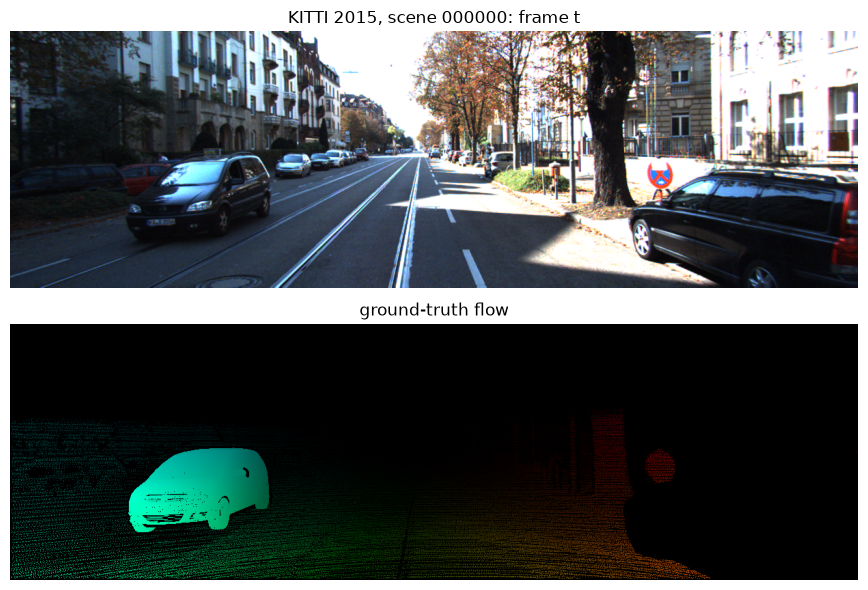

In [ ]:
scenes = flowtools.fetch_kitti(DATA, SCENE_IDS)
s = scenes[0]
mag = float(np.percentile(np.hypot(*s["gt"].transpose(2, 0, 1))[s["valid"]], 99))
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].imshow(s["img0"][..., ::-1]); ax[0].set_title(f"KITTI 2015, scene {s['name']}: frame t")
ax[1].imshow(flowtools.flow_to_bgr(np.where(s["valid"][..., None], s["gt"], 0), mag)[..., ::-1]); ax[1].set_title("ground-truth flow")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Evaluation

In [ ]:
for r in runners.values():
    r.warmup(scenes[0]["img0"], scenes[0]["img1"])

results = []          # one dict per scene
for s in scenes:
    flows = {name: r(s["img0"], s["img1"]) for name, r in runners.items()}
    metrics = {name: flowtools.evaluate(f, s["gt"], s["valid"]) for name, f in flows.items()}
    baseline = flowtools.evaluate(np.zeros_like(s["gt"]), s["gt"], s["valid"])
    results.append(dict(scene=s, flows=flows, metrics=metrics, baseline=baseline, ms={n: r.times_ms[-1] for n, r in runners.items()}))
    print(f"scene {s['name']}: " + " | ".join(f"{n} EPE {m['EPE (px)']:.2f}" for n, m in metrics.items()))

scene 000000: TV-L1 (ours) EPE 51.12 | Horn-Schunck EPE 51.19 | RAFT EPE 8.01
scene 000022: TV-L1 (ours) EPE 17.27 | Horn-Schunck EPE 19.97 | RAFT EPE 1.40
scene 000044: TV-L1 (ours) EPE 10.73 | Horn-Schunck EPE 10.03 | RAFT EPE 1.00
scene 000066: TV-L1 (ours) EPE 47.41 | Horn-Schunck EPE 50.39 | RAFT EPE 7.63
scene 000088: TV-L1 (ours) EPE 34.48 | Horn-Schunck EPE 35.68 | RAFT EPE 3.24
scene 000110: TV-L1 (ours) EPE 35.27 | Horn-Schunck EPE 35.08 | RAFT EPE 2.79
scene 000132: TV-L1 (ours) EPE 30.72 | Horn-Schunck EPE 32.68 | RAFT EPE 2.62
scene 000154: TV-L1 (ours) EPE 13.93 | Horn-Schunck EPE 14.74 | RAFT EPE 0.94
scene 000176: TV-L1 (ours) EPE 53.73 | Horn-Schunck EPE 52.08 | RAFT EPE 22.08
scene 000199: TV-L1 (ours) EPE 26.40 | Horn-Schunck EPE 26.34 | RAFT EPE 1.58


In [ ]:
BASELINE = "Zero flow (baseline)"
rows = [dict(method=n, scene=r["scene"]["name"], **m, ms=r["ms"][n]) for r in results for n, m in r["metrics"].items()]
rows += [dict(method=BASELINE, scene=r["scene"]["name"], **r["baseline"], ms=np.nan) for r in results]
per_scene = pd.DataFrame(rows)
summary = per_scene.groupby("method", sort=False)[["EPE (px)", "Fl-all (%)", "ms"]].mean().rename(columns={"ms": "time per pair (ms)"}).round(2)
summary.to_csv(RESULTS / "kitti_summary.csv")
per_scene.pivot(index="scene", columns="method", values="EPE (px)").round(2).to_csv(RESULTS / "kitti_epe_per_scene.csv")
summary

,EPE (px),Fl-all (%),time per pair (ms)
method,,,
TV-L1 (ours),32.11,68.47,485.84
Horn-Schunck,32.82,70.86,307.29
RAFT,5.13,18.37,150.21
Zero flow (baseline),39.70,87.34,NaN


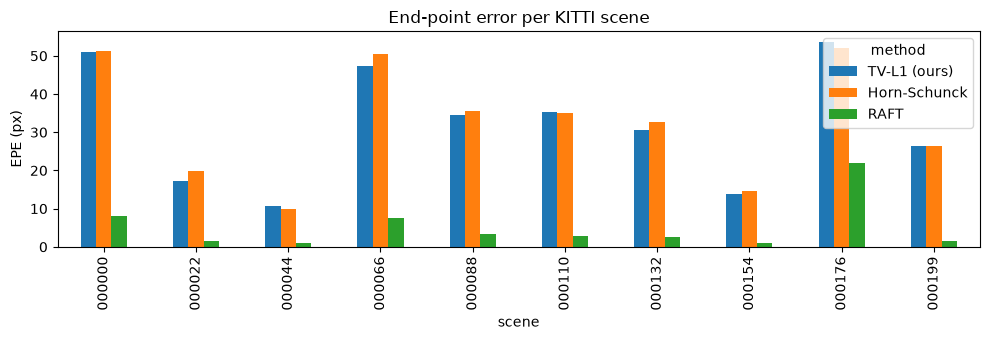

In [ ]:
per_scene.pivot(index="scene", columns="method", values="EPE (px)")[list(runners)].plot.bar(figsize=(10, 3.5), ylabel="EPE (px)", title="End-point error per KITTI scene")
plt.tight_layout(); plt.savefig(RESULTS / "kitti_epe_per_scene.png", dpi=150); plt.show()

## 4. Error versus motion size
Pooled over all pixels of the selected scenes, grouped by the magnitude of the ground-truth motion.

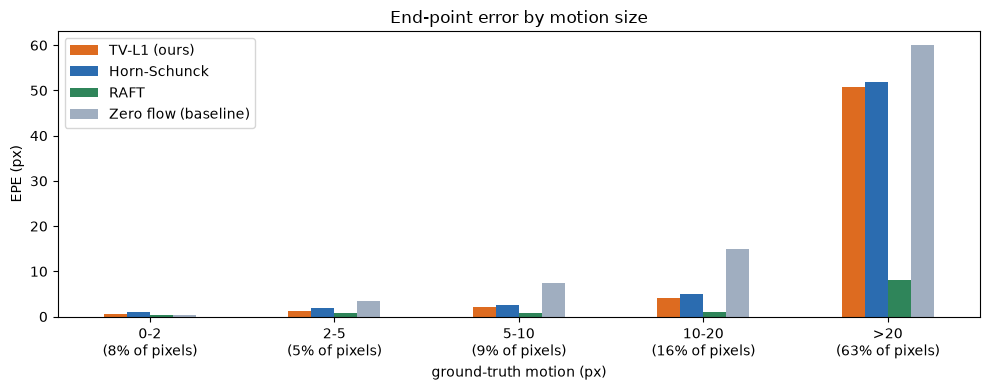

In [ ]:
BINS = [0, 2, 5, 10, 20, np.inf]
BIN_NAMES = ["0-2", "2-5", "5-10", "10-20", ">20"]
sums = {n: np.zeros(len(BIN_NAMES)) for n in [*runners, BASELINE]}
counts = np.zeros(len(BIN_NAMES))
for r in results:
    s = r["scene"]
    for n, f in {**r["flows"], BASELINE: np.zeros_like(s["gt"])}.items():
        a, c = flowtools.epe_by_motion(f, s["gt"], s["valid"], BINS)
        sums[n] += a
    counts += c
by_motion = pd.DataFrame({n: v / counts for n, v in sums.items()}, index=BIN_NAMES)
share = 100 * counts / counts.sum()
ax = by_motion.plot.bar(figsize=(10, 4), rot=0, color=["#dd6b20", "#2b6cb0", "#2f855a", "#a0aec0"], ylabel="EPE (px)", xlabel="ground-truth motion (px)")
ax.set_xticklabels([f"{b}\n({p:.0f}% of pixels)" for b, p in zip(BIN_NAMES, share)])
ax.set_title("End-point error by motion size")
plt.tight_layout(); plt.savefig(RESULTS / "epe_by_motion.png", dpi=150); plt.show()

## 5. Convergence of the dual scheme and the paper's Eq. 17
End-point error against the number of iterations per level on three scenes. The paper prints the dual update of Eq. 17 with a sign that is inconsistent with its Eq. 8 and 10; the curve labelled *as printed* uses it literally, *ours* uses the consistent form.

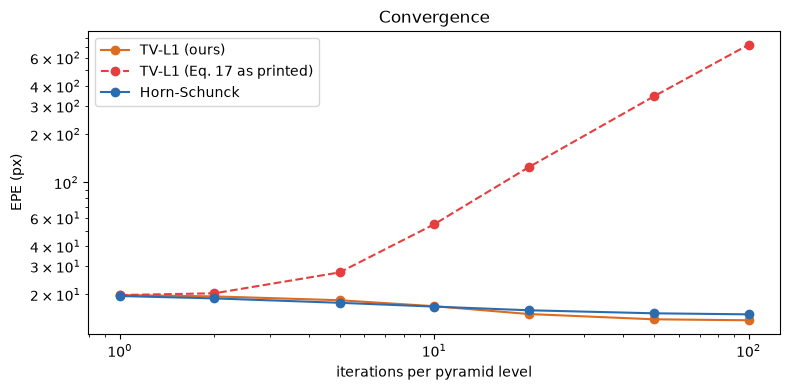

In [ ]:
ITERS = [1, 2, 5, 10, 20, 50, 100]
ITER_SCENES = [r["scene"] for r in results if r["scene"]["name"] in ("000022", "000044", "000154")]
variants = {
    "TV-L1 (ours)": lambda n: TVL1(device=DEVICE, **{**TVL1_PARAMS, "iters": n}),
    "TV-L1 (Eq. 17 as printed)": lambda n: TVL1(device=DEVICE, literal_eq17=True, **{**TVL1_PARAMS, "iters": n}),
    "Horn-Schunck": lambda n: HornSchunck(device=DEVICE, **{**HS_PARAMS, "iters": n}),
}
curves = {name: [] for name in variants}
for n in ITERS:
    for name, make in variants.items():
        solver, errs = make(n), []
        for s in ITER_SCENES:
            f = np.nan_to_num(solver(flowtools.to_gray(s["img0"]), flowtools.to_gray(s["img1"])), nan=1e6, posinf=1e6, neginf=-1e6)
            errs.append(flowtools.evaluate(f, s["gt"], s["valid"])["EPE (px)"])
        curves[name].append(np.mean(errs))
fig, ax = plt.subplots(figsize=(8, 4))
for (name, y), c in zip(curves.items(), ["#dd6b20", "#e53e3e", "#2b6cb0"]):
    ax.plot(ITERS, y, marker="o", label=name, color=c, linestyle="--" if "printed" in name else "-")
ax.set(xscale="log", yscale="log", xlabel="iterations per pyramid level", ylabel="EPE (px)", title="Convergence")
ax.legend(); plt.tight_layout(); plt.savefig(RESULTS / "convergence_eq17.png", dpi=150); plt.show()

## 6. Speed: the paper's real-time claim
Frames per second at the resolutions of the paper's Table 1 (50 iterations), on our GPU. The crosses are the paper's values on a GeForce Go 7900 GTX (2007).

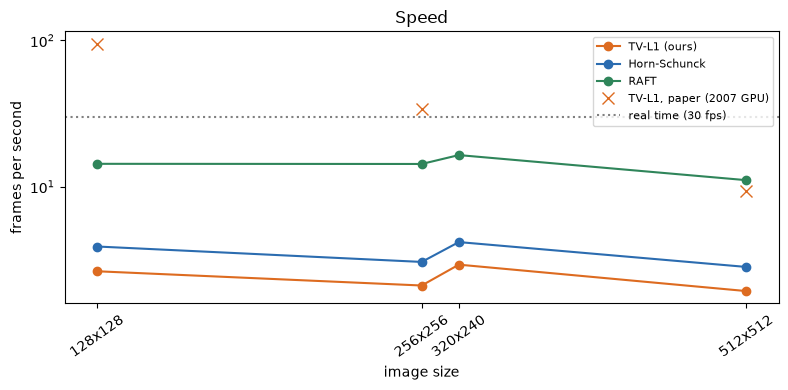

In [ ]:
SIZES = [(128, 128), (256, 256), (320, 240), (512, 512)]
f0, f1 = scenes[0]["img0"], scenes[0]["img1"]
speed = []
for w, h in SIZES:
    a, b = (cv2.resize(x, (w, h), interpolation=cv2.INTER_AREA) for x in (f0, f1))
    for name, r in runners.items():
        t = flowtools.Runner(name, r.fn, r.kind)
        t.warmup(a, b)
        for _ in range(5):
            t(a, b)
        speed.append(dict(method=name, pixels=w * h, fps=1000 / t.ms))
speed = pd.DataFrame(speed)
PAPER_FPS = {128 * 128: 95.0, 256 * 256: 34.1, 512 * 512: 9.3}
fig, ax = plt.subplots(figsize=(8, 4))
for (name, d), c in zip(speed.groupby("method", sort=False), ["#dd6b20", "#2b6cb0", "#2f855a"]):
    ax.plot(d.pixels, d.fps, marker="o", label=name, color=c)
ax.plot(list(PAPER_FPS), list(PAPER_FPS.values()), "x", color="#dd6b20", markersize=9, label="TV-L1, paper (2007 GPU)")
ax.axhline(30, color="grey", linestyle=":", label="real time (30 fps)")
ax.set(xscale="log", yscale="log", xticks=[w * h for w, h in SIZES], xticklabels=[f"{w}x{h}" for w, h in SIZES], xlabel="image size", ylabel="frames per second", title="Speed")
ax.minorticks_off(); ax.tick_params(axis="x", labelrotation=35); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(RESULTS / "speed.png", dpi=150); plt.show()

## 7. The paper's home turf: small motion
The paper targets small-to-moderate motion in video. RubberWhale is a Middlebury benchmark pair with dense ground truth (largest motion about 4 px). We report the average angular error (AAE), the metric used in the paper.

In [ ]:
mb = flowtools.fetch_rubberwhale(DATA)
mb_flows = {n: r(mb["img0"], mb["img1"]) for n, r in runners.items()}
mb_ms = {n: r.times_ms[-1] for n, r in runners.items()}
mb_metrics = {n: flowtools.evaluate(f, mb["gt"], mb["valid"]) for n, f in mb_flows.items()}
mb_table = pd.DataFrame({
    n: {"EPE (px)": m["EPE (px)"], "AAE (deg)": flowtools.angular_error(mb_flows[n], mb["gt"], mb["valid"]), "time (ms)": mb_ms[n]}
    for n, m in mb_metrics.items()}).T
zero = np.zeros_like(mb["gt"])
mb_table.loc[BASELINE] = [flowtools.evaluate(zero, mb["gt"], mb["valid"])["EPE (px)"], flowtools.angular_error(zero, mb["gt"], mb["valid"]), np.nan]
mb_table.round(3).to_csv(RESULTS / "middlebury_rubberwhale.csv")
mb_table.round(3)

c:\Users\stude\anaconda3\envs\opticalflow\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
RubberWhale1.png: 100%|██████████| 361k/361k [00:00<00:00, 12.5MB/s]
RubberWhale2.png: 100%|██████████| 361k/361k [00:00<00:00, 4.55MB/s]
RubberWhale.flo: 100%|██████████| 1.81M/1.81M [00:00<00:00, 21.0MB/s]


,EPE (px),AAE (deg),time (ms)
TV-L1 (ours),0.261,8.489,416.733
Horn-Schunck,0.318,10.355,295.901
RAFT,0.195,6.498,152.785
Zero flow (baseline),1.256,49.641,NaN


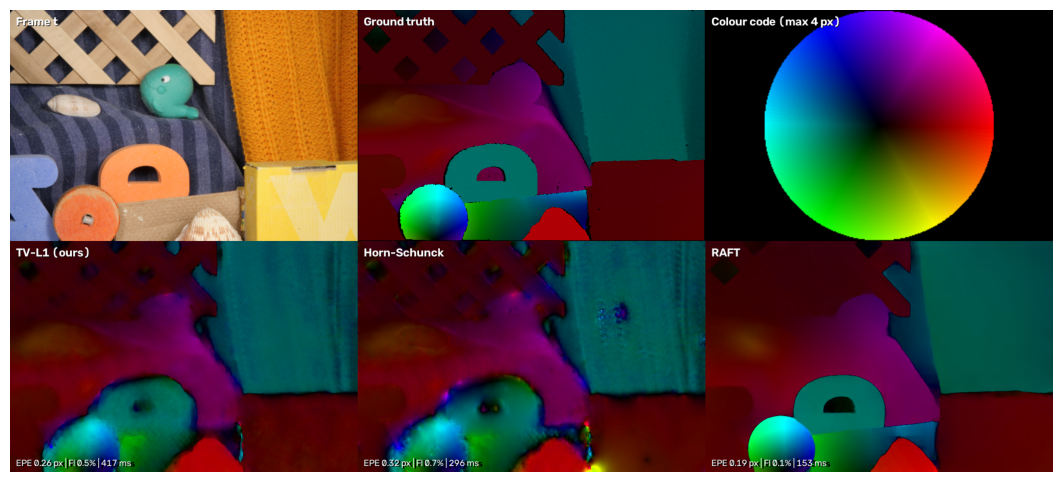

In [ ]:
grid = flowtools.make_grid(flowtools.scene_panels(mb, mb_flows, mb_metrics, mb_ms, 0), cols=3, panel_size=(584, 388))
cv2.imwrite(str(RESULTS / "middlebury_rubberwhale.png"), grid)
plt.figure(figsize=(14, 6)); plt.imshow(grid[..., ::-1]); plt.axis("off"); plt.show()

## 8. Robustness: noise, illumination changes and outliers
The paper claims that the L1 data term makes TV-L1 more robust than quadratic models. We corrupt the second RubberWhale frame and measure the end-point error.

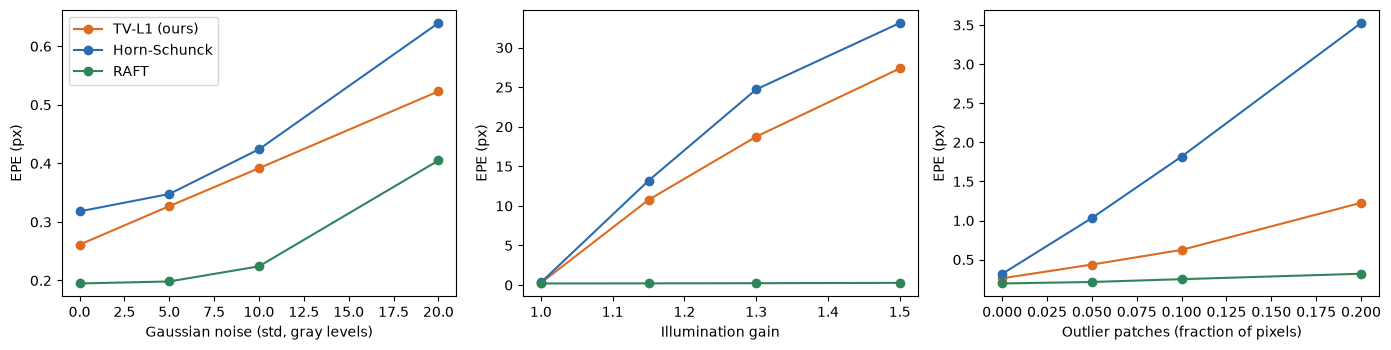

In [ ]:
CORRUPTIONS = {
    "Gaussian noise (std, gray levels)": ([0, 5, 10, 20], flowtools.add_noise),
    "Illumination gain": ([1.0, 1.15, 1.3, 1.5], flowtools.change_gain),
    "Outlier patches (fraction of pixels)": ([0.0, 0.05, 0.1, 0.2], flowtools.add_outliers),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (title, (levels, corrupt)) in zip(axes, CORRUPTIONS.items()):
    curves = {n: [] for n in runners}
    for v in levels:
        img1 = corrupt(mb["img1"], v)
        for n, r in runners.items():
            curves[n].append(flowtools.evaluate(r(mb["img0"], img1, record=False), mb["gt"], mb["valid"])["EPE (px)"])
    for (n, y), c in zip(curves.items(), COLORS):
        ax.plot(levels, y, marker="o", label=n, color=c)
    ax.set(xlabel=title, ylabel="EPE (px)")
axes[0].legend()
plt.tight_layout(); plt.savefig(RESULTS / "robustness.png", dpi=150); plt.show()

## 9. Qualitative comparison (KITTI)

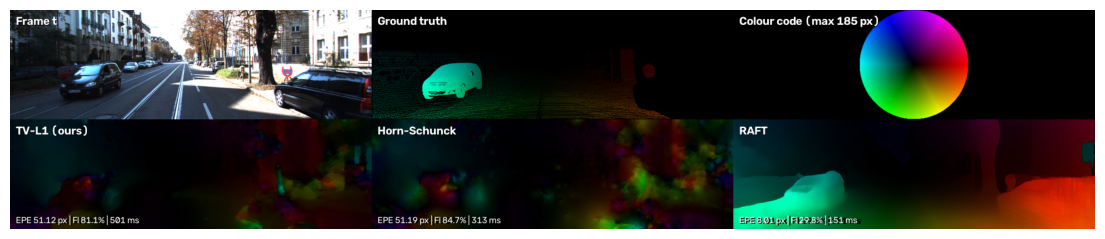

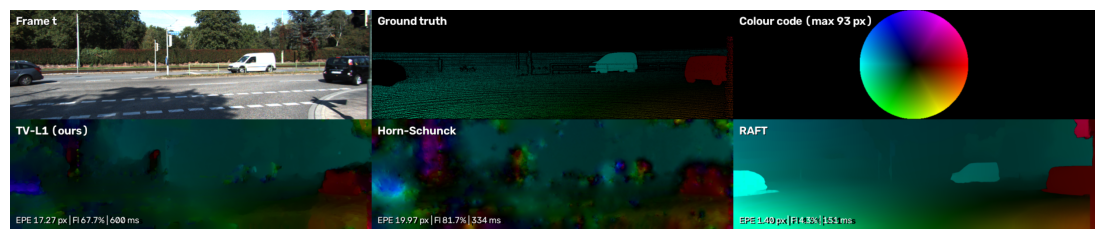

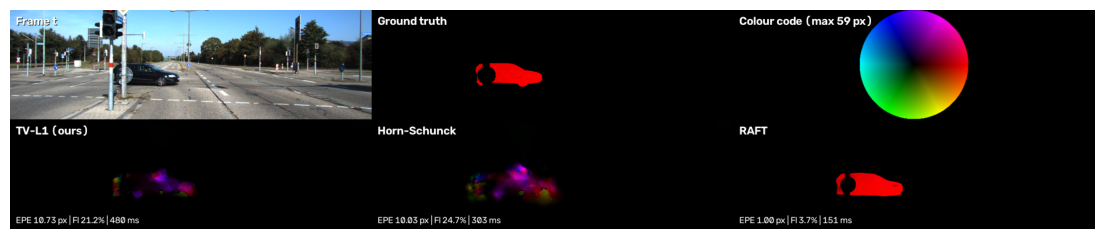

In [ ]:
for r in results[:3]:
    grid = flowtools.make_grid(flowtools.scene_panels(r["scene"], r["flows"], r["metrics"], r["ms"], 0), cols=3)
    cv2.imwrite(str(RESULTS / f"kitti_scene_{r['scene']['name']}.png"), grid)
    plt.figure(figsize=(14, 4.2)); plt.imshow(grid[..., ::-1]); plt.axis("off"); plt.show()

## 10. Comparison video
Each scene is shown for two seconds; the first panel alternates between the two input frames so the motion is visible.

In [ ]:
FPS, SECONDS_PER_SCENE, BLINK_EVERY = 8, 2, 3
writer = None
mb_result = dict(scene=mb, flows=mb_flows, metrics=mb_metrics, ms=mb_ms)
for r in [mb_result] + results:
    for k in range(FPS * SECONDS_PER_SCENE):
        panels = flowtools.scene_panels(r["scene"], r["flows"], r["metrics"], r["ms"], (k // BLINK_EVERY) % 2)
        grid = flowtools.make_grid(panels, cols=3)
        if writer is None:
            writer = flowtools.VideoWriter(RESULTS / "kitti_comparison.mp4", (grid.shape[1], grid.shape[0]), FPS)
        writer.write(grid)
writer.close()
print("saved", RESULTS / "kitti_comparison.mp4")

saved results\kitti_comparison.mp4


## 11. Summary

In [ ]:
ranked = summary.drop(index=BASELINE)
best = lambda col: ranked[col].idxmin()
print(f"Lowest end-point error : {best('EPE (px)')} ({ranked['EPE (px)'].min():.2f} px)")
print(f"Lowest outlier rate    : {best('Fl-all (%)')} ({ranked['Fl-all (%)'].min():.1f} %)")
mb_main = mb_table.drop(index=BASELINE)
print(f"Middlebury (small motion): lowest AAE {mb_main['AAE (deg)'].idxmin()} ({mb_main['AAE (deg)'].min():.2f} deg); TV-L1 (ours) {mb_main.loc['TV-L1 (ours)', 'AAE (deg)']:.2f} deg vs Horn-Schunck {mb_main.loc['Horn-Schunck', 'AAE (deg)']:.2f} deg")
print(f"Fastest                : {best('time per pair (ms)')} ({ranked['time per pair (ms)'].min():.0f} ms per pair)")

Lowest end-point error : RAFT (5.13 px)
Lowest outlier rate    : RAFT (18.4 %)
Middlebury (small motion): lowest AAE RAFT (6.50 deg); TV-L1 (ours) 8.49 deg vs Horn-Schunck 10.35 deg
Fastest                : RAFT (150 ms per pair)


## 12. Conclusion

- **Versus Horn-Schunck, the classical baseline of its time.** On small motion TV-L1 lowers the error from 0.32 to 0.26 px EPE (AAE from 10.4 to 8.5 degrees) for about 1.4 times the runtime, and it is much more robust to outliers: with 20 % corrupted pixels its EPE is 1.2 px against 3.5 px. This is the effect of the L1 data term and the total-variation prior.

- **Limits of the formulation.** Both classical methods rely on brightness constancy and a linearised data term. Global illumination changes break them, and on KITTI, where 63 % of the pixels move more than 20 px, a pyramid with one warp per level is not enough.
- **RAFT (2020)** is the most accurate and the most robust in every experiment, but it needs supervised training on large synthetic datasets. TV-L1 needs no training data and has a handful of interpretable parameters.
- **Speed.** The real-time result of the paper relies on GPU shaders written for the algorithm in 2007. Our PyTorch version runs at 2 to 3 fps and its speed barely changes with the image size, so it is probably limited by per-operation GPU overhead rather than by arithmetic.
- **Reproduction finding.** The dual update printed in Eq. 17 of the paper has a sign that is inconsistent with its Eq. 8 and 10. Implemented literally it diverges; with the consistent sign it converges (Section 5).